In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import charge_trap_pot_model_4_layers as ctm 
import time


np.set_printoptions(threshold=sys.maxsize)

In [ ]:
NSM = int(60/2)            # number of sm x lattice points
M = int(60/2)              # should be atleast thrice confinement length
AX = int(5*2)              # lattice spacing in nm
AY = int(5*2)              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = int(800/2)
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

### default values of dielectric ocnstant taken

ModCT = ctm.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48, t_ge=20)


lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 66.31720133634798
mu =  1.9789724682017418


In [3]:
XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100/2*AY
b = 0
c = M*AY
d = (M+100/2)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

#n_ab = 5  # number of points between a and b
#n_bc = 11  # number of points between b and c (more points)
#n_cd = 5  # number of points between c and d


# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

#print(YCT)

#YCT = np.linspace(-200*AY,(M+200)*AY,101)

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57

print('X co-ordinate of charge trap =', XCT )

Ep = np.empty((YCT.shape[0],K_NUM))

H_wo_CT = ModCT.H_sys(PHI, 'li', XCT, YCT[0], ZCT, ZIM, ZQW, f_ct=0)

for i in range(YCT.shape[0]):
    print(YCT[i], i)

    H_CT = ModCT.H_charge_trap_sys(XCT, YCT[i], ZCT, ZIM, ZQW)
    
    #t2 = time.perf_counter()
    
    H = H_CT + H_wo_CT

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep[i,:] = Es

    if i%10==0:
        print(Ep[i,:])

np.save('linear_E_vs_yct_image_chrg_model_full_4_layers_full_pts_Vfinal_ax_ay_10_10.npy.npy', Ep)

X co-ordinate of charge trap = 4150.0
-500.0 0
[-0.07700256 -0.07682754  0.07682754  0.07700256]
-490.0 1
-480.0 2
-470.0 3
-460.0 4
-450.0 5
-440.0 6
-430.0 7
-420.0 8
-410.0 9
-400.0 10
[-0.07699951 -0.07682454  0.07682454  0.07699951]
-390.0 11
-380.0 12
-370.0 13
-360.0 14
-350.0 15
-340.0 16
-330.0 17
-320.0 18
-310.0 19
-300.0 20
[-0.07699309 -0.07681822  0.07681822  0.07699309]
-290.0 21
-280.0 22
-270.0 23
-260.0 24
-250.0 25
-240.0 26
-230.0 27
-220.0 28
-210.0 29
-200.0 30
[-0.0769771  -0.07680246  0.07680246  0.0769771 ]
-190.0 31
-180.0 32
-170.0 33
-160.0 34
-150.0 35
-140.0 36
-130.0 37
-120.0 38
-110.0 39
-100.0 40
[-0.07692594 -0.07675207  0.07675207  0.07692594]
-90.0 41
-80.0 42
-70.0 43
-60.0 44
-50.0 45
-40.0 46
-30.0 47
-20.0 48
-10.0 49
0.0 50
[-0.07668794 -0.07651752  0.07651752  0.07668794]
2.9702970297029703 51
5.9405940594059405 52
8.910891089108912 53
11.881188118811881 54
14.85148514851485 55
17.821782178217823 56
20.792079207920793 57
23.762376237623762 58


In [5]:
np.save('linear_E_vs_yct_image_chrg_model_full_4_layers_full_pts_Vfinal_ax_ay_10_10.npy', Ep)

In [6]:
#Ep_cu_mm2d = np.load('cubic_E_vs_yct_Zdiff_14_wider_yct_width_75nm_refined.npy')
Ep_li_ctm = np.load('linear_E_vs_yct_image_chrg_model_full_4_layers_full_pts_Vfinal_ax_ay_10_10.npy')

Text(0, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

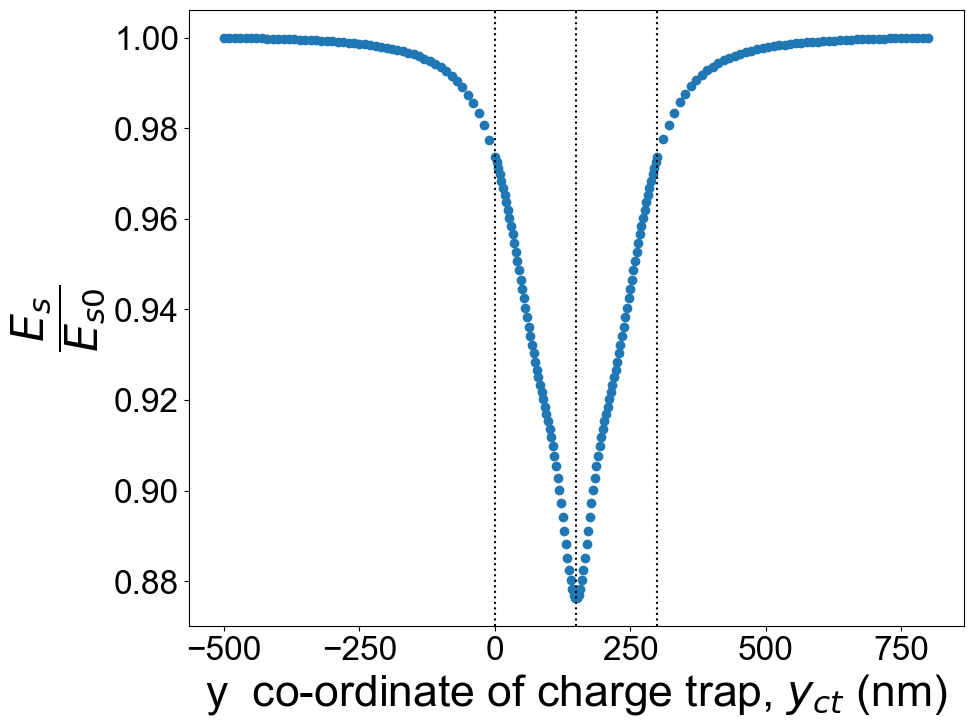

In [7]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

ax = plt.axis()

linear_spin_split = Ep_li_ctm[:, K_NUM//2+1]-Ep_li_ctm[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

Ep_wct = (Ep_li_ctm[:, K_NUM//2+1]-Ep_li_ctm[:, K_NUM//2])/max_spin_split


plt.scatter(YCT, Ep_wct )
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')
plt.axvline(x=M/2*AY, color='black', linestyle='dotted')

plt.xlabel(r'y  co-ordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)

#plt.ylim(ymin=0)